<a href="https://colab.research.google.com/github/rashidkhan-dev0101/Neaural-Network-model/blob/main/Build_a_Neural_Network_with_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Select GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.11.0+cpu
Device: cpu


In [2]:

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)


100%|██████████| 9.91M/9.91M [00:00<00:00, 52.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.71MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.55MB/s]

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5


In [6]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Batch size:", batch_size)
print("Number of training batches:", len(train_loader))
print("Number of testing batches:", len(test_loader))


Batch size: 64
Number of training batches: 938
Number of testing batches: 157


In [8]:
import torch
import torch.nn as nn

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x


model = DigitClassifier().to(device)

print(model)
print("Device:", device)


DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Device: cpu


In [9]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)


Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [10]:
criterion = nn.CrossEntropyLoss()

loss = criterion(outputs, labels)

print("Loss:", loss.item())

Loss: 2.288264513015747


In [11]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer created!")

Optimizer created!


In [12]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Calculate current loss
loss = criterion(outputs, labels)

print("Loss:", loss.item())
print("Optimizer:", optimizer)

Loss: 2.288264513015747
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [13]:
optimizer.zero_grad()

In [14]:
loss.backward()

In [15]:
optimizer.step()

In [17]:
# Get a fresh batch
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

# 1. Forward pass
outputs = model(images)

# 2. Calculate loss
loss = criterion(outputs, labels)

# 3. Clear old gradients
optimizer.zero_grad()

# 4. Backpropagation
loss.backward()

# 5. Update weights
optimizer.step()

print("Loss:", loss.item())
print("Weights updated successfully!")

Loss: 2.274874687194824
Weights updated successfully!


In [18]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        # Move data to the device
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Add this batch's loss
        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.3435
Epoch [2/5], Loss: 0.1616
Epoch [3/5], Loss: 0.1112
Epoch [4/5], Loss: 0.0846
Epoch [5/5], Loss: 0.0666


In [19]:
model.eval()

DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [20]:
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Get predictions
        outputs = model(images)

        # Find the class with the highest output
        _, predicted = torch.max(outputs, 1)

        # Count total predictions
        total += labels.size(0)

        # Count correct predictions
        correct += (predicted == labels).sum().item()

accuracy = correct / total

print("Correct predictions:", correct)
print("Total test images:", total)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Correct predictions: 9743
Total test images: 10000
Test Accuracy: 97.43%


In [21]:
import matplotlib.pyplot as plt

# Get one batch from the test dataset
images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

# Make predictions
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

print("Predictions:", predicted[:10].cpu().numpy())
print("Actual:", labels[:10].cpu().numpy())

Predictions: [7 2 1 0 4 1 4 9 5 9]
Actual: [7 2 1 0 4 1 4 9 5 9]


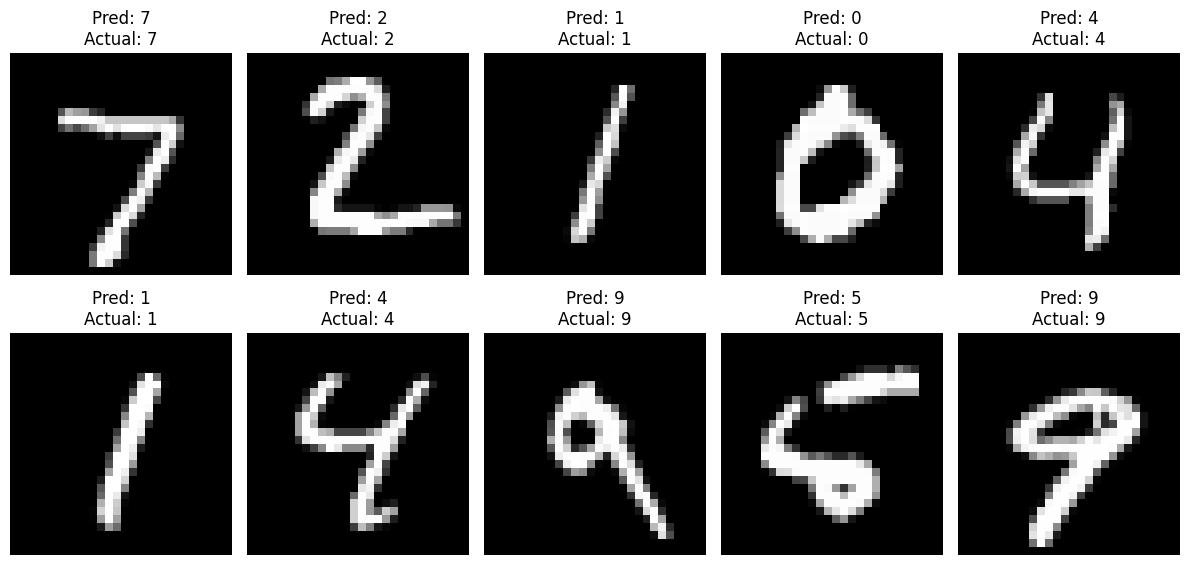

In [22]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].cpu().squeeze(), cmap="gray")

    plt.title(
        f"Pred: {predicted[i].item()}\n"
        f"Actual: {labels[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
wrong = predicted != labels

wrong_indices = torch.where(wrong)[0]

print("Wrong predictions in this batch:", len(wrong_indices))
plt.figure(figsize=(12, 6))

num_images = min(10, len(wrong_indices))

for i in range(num_images):
    index = wrong_indices[i].item()

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        images[index].cpu().squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Pred: {predicted[index].item()}\n"
        f"Actual: {labels[index].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Wrong predictions in this batch: 0


<Figure size 1200x600 with 0 Axes>

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Total predictions:", len(all_predictions))
print("Total labels:", len(all_labels))

Total predictions: 10000
Total labels: 10000


In [26]:
cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[ 970    0    1    2    2    1    1    1    1    1]
 [   0 1118    4    1    0    1    3    2    6    0]
 [   7    0  994   10    3    0    4    6    7    1]
 [   0    0    0  988    0   10    0    8    2    2]
 [   2    0    1    0  957    0    7    2    2   11]
 [   2    0    0    8    1  872    5    0    3    1]
 [   8    2    1    1    4    4  936    0    2    0]
 [   2    5    8    1    0    0    0 1004    1    7]
 [   3    0    3   14    5    6    5    5  930    3]
 [   3    4    0    9    7    4    0    6    2  974]]


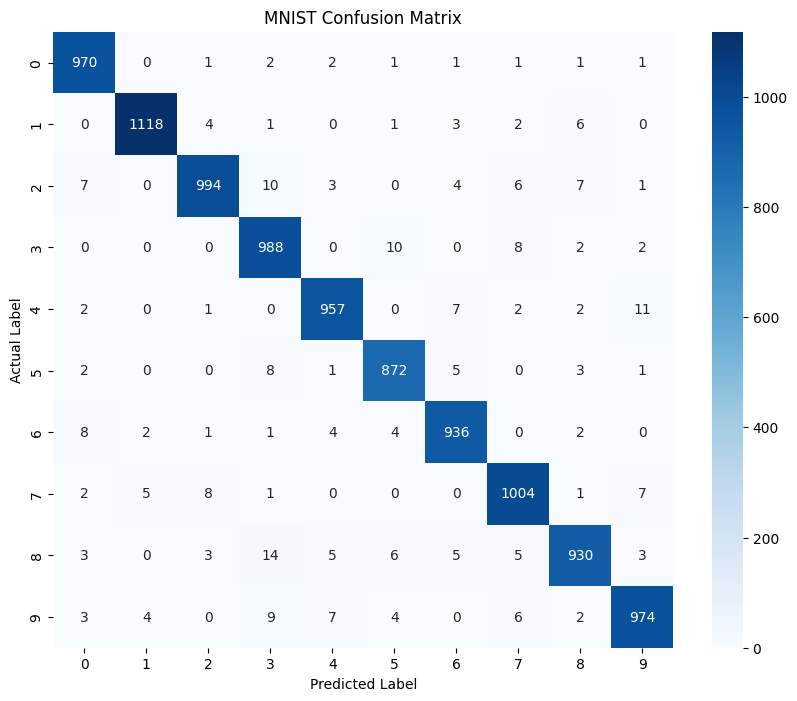

In [27]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MNIST Confusion Matrix")

plt.show()